# Projeto A3 — Checkpoint 3: Modelagem Preditiva & Data Storytelling

**Unidade Curricular:** Análise de Dados e Big Data (0005073) · Semestre 2026/2  
**Tema:** Microestrutura do Bitcoin (BTC/USDT) em uma semana de estresse (19–25/02/2025)

Este notebook consome diretamente os produtos processados em `data/processed/` por meio do pacote consolidado [`src/`](../src/), executando:
1. **Modelagem Preditiva (Parte 2 do CP3):** previsão de volatilidade (regressão) e direção do retorno (classificação) em horizontes de `1min` e `1s`, com atributos estritamente defasados (*zero look-ahead*), validação temporal *walk-forward* e análise de viabilidade operacional frente aos custos da mesa.
2. **Data Storytelling (Parte 4 do CP3):** narrativa executiva **"Da calmaria ao estresse"** com gráficos consolidados e matriz de decisão para a mesa de execução.
3. **Referência a Governança e Ética (Parte 5 do CP3):** síntese de conformidade com LGPD, licença e riscos de sinal (detalhados em [`ETHICS_LGPD.md`](../ETHICS_LGPD.md)).


## 1. Configuração e Carregamento Consolidado (`src/`)

Caso os arquivos em `data/processed/` ainda não existam no ambiente local, `run_etl_pipeline()` executa o download verificado (SHA-256) e gera os Parquets automaticamente.


In [1]:
import sys
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
from matplotlib.patches import Patch

BASE_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(BASE_DIR) not in sys.path:
    sys.path.insert(0, str(BASE_DIR))

from src.config import DAY_COLORS, PALETTE, SIZE_LABELS, day_label
from src.data_loader import (
    compute_daily_summary,
    compute_hourly_profile,
    compute_lag_correlations,
    compute_trade_size_summary,
    load_bars,
    load_taker_orders,
)
from src.etl import run_etl_pipeline
from src.modeling import (
    prepare_modeling_dataset,
    run_direction_walk_forward,
    run_volatility_walk_forward,
    summarize_walk_forward,
)

# Garante que data/processed/ esteja materializado (idempotente)
output_paths = run_etl_pipeline(BASE_DIR, verbose=True)

# Estilo visual consistente com o Checkpoint 2
SURFACE, INK, INK_2 = PALETTE["surface"], PALETTE["ink"], PALETTE["ink_2"]
GRID, AXIS = PALETTE["grid"], PALETTE["axis"]
BLUE, ORANGE, RED, TEAL = PALETTE["blue"], PALETTE["orange"], PALETTE["red"], PALETTE["teal"]

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 110, "figure.figsize": (11, 4.2), "figure.constrained_layout.use": True,
    "font.size": 10, "axes.titlesize": 11, "axes.titlecolor": INK_2, "axes.titlelocation": "left",
    "axes.labelcolor": INK_2, "axes.edgecolor": AXIS, "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "xtick.color": AXIS, "ytick.color": AXIS, "xtick.labelcolor": INK_2, "ytick.labelcolor": INK_2,
    "lines.linewidth": 2, "legend.frameon": False, "legend.labelcolor": INK_2,
    "text.parse_math": False,
})

def br(x, nd=0):
    s = f"{x:,.{nd}f}"
    return s.replace(",", "X").replace(".", ",").replace("X", ".")

def br_pct(frac, nd=1):
    return f"{br(frac * 100, nd)} %"

def headline(fig, text):
    fig.suptitle(text, x=0.01, ha="left", fontsize=13, fontweight="bold", color=INK)

def styled(df, nd=2):
    return df.style.format(precision=nd, thousands=".", decimal=",", na_rep="—")


Todos os arquivos em data/processed/ já existem. Use force=True para regerar.


In [2]:
bars_1m = load_bars("1min", BASE_DIR)
bars_1s = load_bars("1s", BASE_DIR)
daily = compute_daily_summary(bars_1m)
trade_size = compute_trade_size_summary(BASE_DIR, use_cache=True)
taker_orders = load_taker_orders(BASE_DIR, columns=["ts", "side", "n_fills", "notional_usd", "book_walk_bps", "size_bucket"])

print(f"bars_1min: {br(len(bars_1m))} linhas | bars_1s: {br(len(bars_1s))} linhas | taker_orders: {br(len(taker_orders))} linhas")
styled(daily[["day_label", "tipo", "abertura", "fechamento", "retorno_pct", "amplitude_pct", "vol_realizada_pct", "saldo_fluxo_pct"]].set_index("day_label"), nd=2)


bars_1min: 10.080 linhas | bars_1s: 604.800 linhas | taker_orders: 4.555.252 linhas


,tipo,abertura,fechamento,retorno_pct,amplitude_pct,vol_realizada_pct,saldo_fluxo_pct
day_label,,,,,,,
qua 19/02,dia útil,"95.671,74","96.644,37","1,02","1,97","1,69","-12,72"
qui 20/02,dia útil,"96.644,37","98.305,00","1,72","2,38","1,48","-2,02"
sex 21/02,estresse,"98.305,01","96.181,98","-2,16","4,85","2,45","-5,03"
sáb 22/02,fim de semana,"96.181,99","96.551,01","0,38","1,26","0,97","-6,05"
dom 23/02,fim de semana,"96.551,01","96.258,00","-0,30","1,49","0,93","-15,11"
seg 24/02,estresse,"96.258,00","91.552,88","-4,89","5,64","2,56","-8,47"
ter 25/02,estresse,"91.552,88","88.680,40","-3,14","7,54","4,72","-8,54"


---
## 2. Formulação Preditiva e Engenharia de Atributos sem *Look-Ahead*

Para apoiar a mesa de execução, formulamos **dois problemas distintos** sobre o próximo intervalo $t + 1$, usando exclusivamente informações disponíveis no fechamento do intervalo $t$ ($\le t$):

| Tarefa | Alvo ($t+1$) | Tipo | Uso potencial na mesa |
|---|---|---|---|
| **A. Volatilidade** | `target_range_bps` $= (\text{high}_{t+1}/\text{low}_{t+1} - 1)\times 10^4$ e `target_abs_ret_bps` | Regressão | Calibrar limites dinâmicos de risco, *stop/slippage* esperado e fatiamento TWAP/VWAP |
| **B. Direção do retorno** | `target_dir` $= \mathbb{I}(\text{log\_return}_{t+1} > 0)$ | Classificação binária | Avaliar se desequilíbrio de fluxo gera alfa direcional líquido de taxas (*taker fee*) |

### Controle estrito contra vazamento de futuro (*look-ahead bias*)
- **Atributos causais (`build_lagged_features`):** defasagens $0, 1, 2, 3, 5$ (onde `t0` é o intervalo $t$ recém-fechado), médias móveis e desvios-padrão em janelas passadas ($5, 15, 60$), interação `ofi × log_vol`, razão de aceleração de amplitude (`5/60`) e codificação cíclica determinística da hora (`sin_hour`, `cos_hour`).
- **Grupos de variáveis testados (ablação):** `apenas_ofi` → `fluxo_e_atividade` → `completo`.
- **Validação temporal *walk-forward* expansiva:** treinamos inicialmente nos dias 19–20/02 (2.880 minutos) e avaliamos o dia seguinte (21/02) estritamente fora da amostra; a cada dobra, expandimos o histórico de treino em +1 dia até 25/02 (5 dobras cronológicas cobrindo dias calmos e de estresse). Escalonadores (`StandardScaler`) ajustam-se **exclusivamente dentro da dobra de treino**.


In [3]:
feats_1m, targets_1m, fsets_1m = prepare_modeling_dataset(bars_1m)
print(f"Dataset 1min pronto: {br(len(feats_1m))} observações válidas × {feats_1m.shape[1]} features")
print("Tamanhos dos conjuntos:", {k: len(v) for k, v in fsets_1m.items()})

# Prova empírica de ausência de vazamento: perturbar t > 1000 não altera features em <= 1000
bars_test = bars_1m.copy()
bars_test.iloc[1001:, bars_test.columns.get_loc("close")] *= 3.0
bars_test.iloc[1001:, bars_test.columns.get_loc("ofi")] = -1.0
feats_pert, _, _ = prepare_modeling_dataset(bars_test)
assert feats_1m.iloc[:900].equals(feats_pert.iloc[:900]), "Vazamento detectado!"
print("Verificação anti-vazamento (zero look-ahead): OK ✅")


Dataset 1min pronto: 10.019 observações válidas × 50 features
Tamanhos dos conjuntos: {'apenas_ofi': 8, 'fluxo_e_atividade': 23, 'completo': 50}
Verificação anti-vazamento (zero look-ahead): OK ✅


### 2.1 Previsão de Volatilidade (`1min`, *Walk-Forward*)
Comparamos baselines ingênuos (**Persistência**, **Média móvel 15 min**), modelo linear (**Ridge**) e modelo não linear baseado em árvores (**HistGradientBoostingRegressor**).


In [4]:
vol_folds_1m, vol_preds_1m = run_volatility_walk_forward(feats_1m, targets_1m, fsets_1m, target_col="target_range_bps")
vol_sum_1m = summarize_walk_forward(vol_folds_1m, ["mae_bps", "rmse_bps", "r2", "spearman"])
display(styled(vol_sum_1m.set_index("modelo"), nd=3))

abs_folds_1m, _ = run_volatility_walk_forward(feats_1m, targets_1m, fsets_1m, target_col="target_abs_ret_bps")
abs_sum_1m = summarize_walk_forward(abs_folds_1m, ["mae_bps", "rmse_bps", "r2", "spearman"])
print("\nAlvo alternativo — |log_return| do próximo minuto (bps):")
display(styled(abs_sum_1m.set_index("modelo"), nd=3))


,família,mae_bps,rmse_bps,r2,spearman
modelo,,,,,
Persistência (t),baseline,"3,296","4,871","0,074","0,530"
Média móvel (15),baseline,"2,775","4,154","0,353","0,603"
Ridge (apenas OFI),linear,"5,297","7,265","-0,963","0,044"
Ridge (completo),linear,"2,668","3,999","0,385","0,616"
HistGradientBoosting (fluxo+ativ.),não linear,"2,924","4,414","0,301","0,583"
HistGradientBoosting (completo),não linear,"2,835","4,320","0,314","0,574"



Alvo alternativo — |log_return| do próximo minuto (bps):


,família,mae_bps,rmse_bps,r2,spearman
modelo,,,,,
Persistência (t),baseline,"3,576","5,235","-0,482","0,222"
Média móvel (15),baseline,"2,749","3,989","0,146","0,366"
Ridge (apenas OFI),linear,"3,465","5,139","-0,480","0,023"
Ridge (completo),linear,"2,715","3,943","0,154","0,370"
HistGradientBoosting (fluxo+ativ.),não linear,"2,770","4,085","0,111","0,342"
HistGradientBoosting (completo),não linear,"2,782","4,070","0,110","0,336"


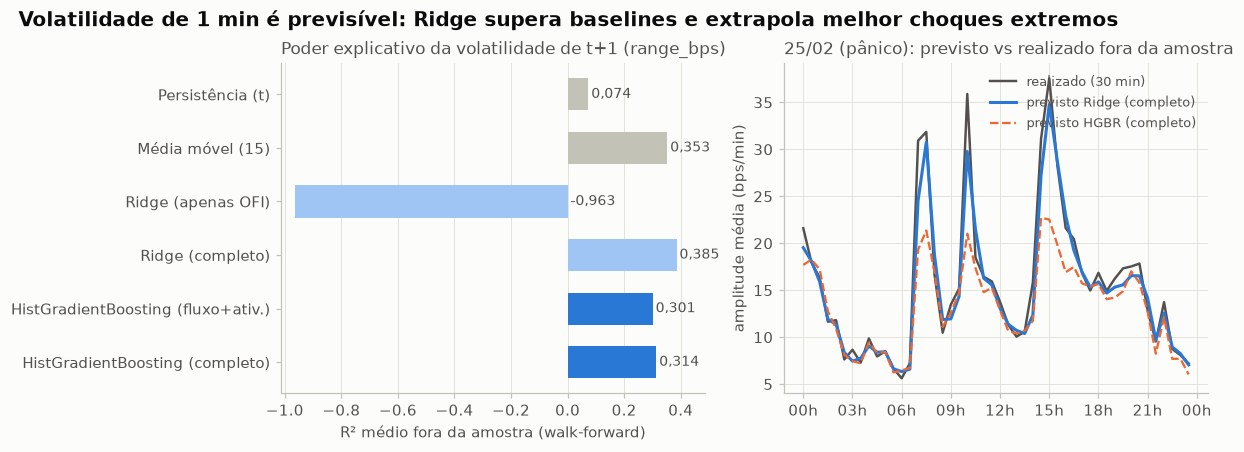

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.0))

# Painel A: Comparação de R² e Spearman entre modelos
ax = axes[0]
y_pos = np.arange(len(vol_sum_1m))
colors_m = [AXIS if f == "baseline" else "#9ec5f4" if f == "linear" else BLUE for f in vol_sum_1m["família"]]
ax.barh(y_pos, vol_sum_1m["r2"], color=colors_m, height=0.6)
ax.set_yticks(y_pos, vol_sum_1m["modelo"])
ax.invert_yaxis()
ax.set_xlabel("R² médio fora da amostra (walk-forward)")
ax.set_title("Poder explicativo da volatilidade de t+1 (range_bps)")
for y, v in enumerate(vol_sum_1m["r2"]):
    ax.text(max(v, 0) + 0.01, y, br(v, 3), va="center", fontsize=9, color=INK_2)
ax.set_xlim(min(0, vol_sum_1m["r2"].min() - 0.05), vol_sum_1m["r2"].max() + 0.1)
ax.grid(axis="y", visible=False)

# Painel B: Série prevista vs realizada no pior dia de estresse (25/02, Ridge vs HGBR)
ax = axes[1]
sub_ridge = vol_preds_1m[(vol_preds_1m["dia_teste"] == "2025-02-25") & (vol_preds_1m["modelo"] == "Ridge (completo)")].set_index("ts")
sub_hgbr = vol_preds_1m[(vol_preds_1m["dia_teste"] == "2025-02-25") & (vol_preds_1m["modelo"] == "HistGradientBoosting (completo)")].set_index("ts")
real_hr = sub_ridge["y_true"].resample("30min").mean()
ridge_hr = sub_ridge["y_pred"].resample("30min").mean()
hgbr_hr = sub_hgbr["y_pred"].resample("30min").mean()
ax.plot(real_hr.index, real_hr.values, color=INK_2, linewidth=1.6, label="realizado (30 min)")
ax.plot(ridge_hr.index, ridge_hr.values, color=BLUE, linewidth=2.0, label="previsto Ridge (completo)")
ax.plot(hgbr_hr.index, hgbr_hr.values, color=ORANGE, linewidth=1.5, linestyle="--", label="previsto HGBR (completo)")
ax.set_title("25/02 (pânico): previsto vs realizado fora da amostra")
ax.set_ylabel("amplitude média (bps/min)")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Hh"))
ax.legend(loc="upper right", fontsize=8.5)

headline(fig, "Volatilidade de 1 min é previsível: Ridge supera baselines e extrapola melhor choques extremos")
plt.show()


### 2.2 Previsão de Direção do Retorno (`1min`, *Walk-Forward*)
Agora testamos se OFI, volume e amplitude passados antecipam o **sinal do retorno** do próximo minuto ($\text{retorno}_{t+1} > 0$) e se um eventual sinal supera custos reais de execução (*taker fee* na Binance spot ≈ 2 a 10 bps por perna).


In [6]:
dir_folds_1m, _ = run_direction_walk_forward(feats_1m, targets_1m, fsets_1m)
dir_sum_1m = summarize_walk_forward(
    dir_folds_1m,
    ["accuracy", "balanced_acc", "roc_auc", "log_loss", "retorno_bruto_bps", "retorno_top10_bps"],
)
display(styled(dir_sum_1m.set_index("modelo"), nd=3))


,família,accuracy,balanced_acc,roc_auc,log_loss,retorno_bruto_bps,retorno_top10_bps
modelo,,,,,,,
Classe majoritária,baseline,"0,510","0,500","0,500","0,693","0,091","0,091"
Persistência de sinal (t),baseline,"0,530","0,529","0,529","2,172","0,257","0,257"
Logit (apenas OFI),linear,"0,526","0,524","0,536","0,691","0,155","0,360"
Logit (completo),linear,"0,517","0,516","0,523","0,699","-0,004","-0,178"
HistGradientBoosting (fluxo+ativ.),não linear,"0,520","0,520","0,521","0,705","0,172","0,330"
HistGradientBoosting (completo),não linear,"0,511","0,511","0,513","0,709","0,015","-0,119"


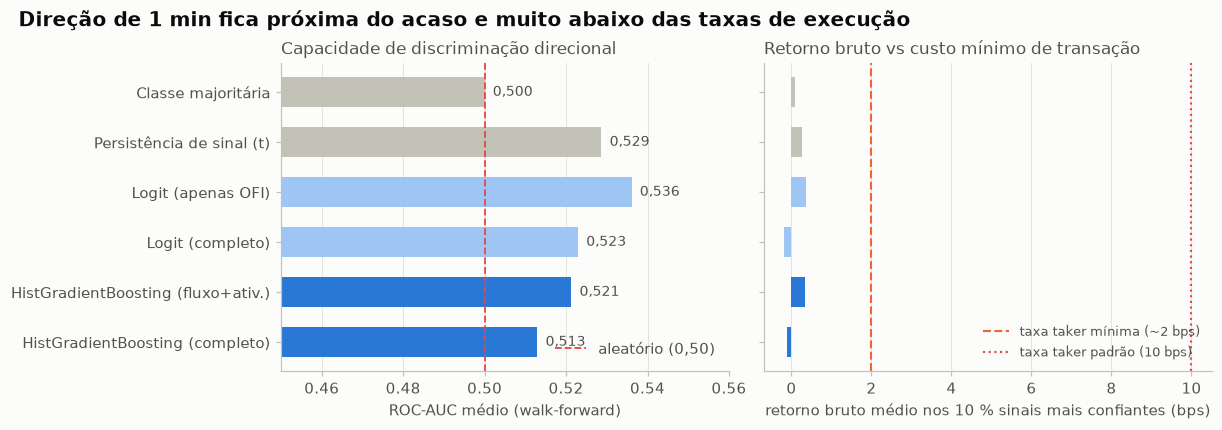

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))

ax = axes[0]
y_pos = np.arange(len(dir_sum_1m))
colors_d = [AXIS if f == "baseline" else "#9ec5f4" if f == "linear" else BLUE for f in dir_sum_1m["família"]]
ax.barh(y_pos, dir_sum_1m["roc_auc"], color=colors_d, height=0.6)
ax.axvline(0.5, color=RED, linestyle="--", linewidth=1.2, label="aleatório (0,50)")
ax.set_yticks(y_pos, dir_sum_1m["modelo"])
ax.invert_yaxis()
ax.set_xlim(0.45, max(0.56, dir_sum_1m["roc_auc"].max() + 0.02))
ax.set_xlabel("ROC-AUC médio (walk-forward)")
ax.set_title("Capacidade de discriminação direcional")
for y, v in enumerate(dir_sum_1m["roc_auc"]):
    ax.text(v + 0.002, y, br(v, 3), va="center", fontsize=9, color=INK_2)
ax.legend(loc="lower right")
ax.grid(axis="y", visible=False)

ax = axes[1]
ax.barh(y_pos, dir_sum_1m["retorno_top10_bps"], color=colors_d, height=0.6)
ax.axvline(2.0, color=ORANGE, linestyle="--", linewidth=1.4, label="taxa taker mínima (~2 bps)")
ax.axvline(10.0, color=RED, linestyle=":", linewidth=1.4, label="taxa taker padrão (10 bps)")
ax.set_yticks(y_pos, [""] * len(dir_sum_1m))
ax.invert_yaxis()
ax.set_xlabel("retorno bruto médio nos 10 % sinais mais confiantes (bps)")
ax.set_title("Retorno bruto vs custo mínimo de transação")
ax.legend(loc="lower right", fontsize=8.5)
ax.grid(axis="y", visible=False)

headline(fig, "Direção de 1 min fica próxima do acaso e muito abaixo das taxas de execução")
plt.show()


---
## 3. Teste em Horizonte Mais Curto: Barras de 1 Segundo (`1s`, 604.800 barras)

No Checkpoint 2 levantamos a hipótese de que o poder preditivo do OFI pudesse aparecer em escalas menores que 1 minuto. Testamos agora o mesmo pipeline causal e *walk-forward* sobre as **604.800 barras de 1 segundo** (com preenchimento sem *look-ahead*). Na classificação direcional em `1s`, avaliamos os segundos em que há variação de preço (`target_ret_bps != 0`), evitando que segundos planos inflamem artificialmente a acurácia.


In [8]:
feats_1s, targets_1s, fsets_1s = prepare_modeling_dataset(bars_1s)
print(f"Dataset 1s pronto: {br(len(feats_1s))} segundos válidos × {feats_1s.shape[1]} features")

vol_folds_1s, _ = run_volatility_walk_forward(feats_1s, targets_1s, fsets_1s, target_col="target_range_bps")
vol_sum_1s = summarize_walk_forward(vol_folds_1s, ["mae_bps", "rmse_bps", "r2", "spearman"])
print("Volatilidade (range_bps) — 1 segundo:")
display(styled(vol_sum_1s.set_index("modelo"), nd=3))

dir_folds_1s, _ = run_direction_walk_forward(feats_1s, targets_1s, fsets_1s, exclude_zero_returns=True)
dir_sum_1s = summarize_walk_forward(
    dir_folds_1s,
    ["accuracy", "balanced_acc", "roc_auc", "log_loss", "retorno_bruto_bps", "retorno_top10_bps"],
)
print("\nDireção do retorno (excluindo retornos nulos) — 1 segundo:")
display(styled(dir_sum_1s.set_index("modelo"), nd=3))


Dataset 1s pronto: 604.739 segundos válidos × 51 features


Volatilidade (range_bps) — 1 segundo:


,família,mae_bps,rmse_bps,r2,spearman
modelo,,,,,
Persistência (t),baseline,"0,341","0,719","-0,465","0,352"
Média móvel (15),baseline,"0,306","0,556","0,121","0,380"
Ridge (apenas OFI),linear,"0,369","0,666","-0,149","0,100"
Ridge (completo),linear,"0,302","0,543","0,164","0,427"
HistGradientBoosting (fluxo+ativ.),não linear,"0,312","0,560","0,126","0,434"
HistGradientBoosting (completo),não linear,"0,306","0,550","0,150","0,430"



Direção do retorno (excluindo retornos nulos) — 1 segundo:


,família,accuracy,balanced_acc,roc_auc,log_loss,retorno_bruto_bps,retorno_top10_bps
modelo,,,,,,,
Classe majoritária,baseline,"0,503","0,500","0,500","0,693","-0,004","-0,004"
Persistência de sinal (t),baseline,"0,456","0,457","0,457","2,511","0,117","0,117"
Logit (apenas OFI),linear,"0,549","0,549","0,582","0,685","-0,096","-0,106"
Logit (completo),linear,"0,635","0,635","0,695","0,633","0,082","0,135"
HistGradientBoosting (fluxo+ativ.),não linear,"0,676","0,676","0,754","0,573","0,105","0,061"
HistGradientBoosting (completo),não linear,"0,781","0,781","0,837","0,470","0,106","0,054"


### 3.1 Viabilidade Operacional para a Mesa de Execução

| Dimensão | Achado em `1min` e `1s` | Veredito operacional |
|---|---|---|
| **Previsão de volatilidade** | Em `1min`, `Ridge (completo)` atinge $R^2 \approx 0{,}385$ e Spearman $\approx 0{,}616$ (superando a média móvel de 15 min, $R^2 \approx 0{,}353$, e modelos de árvore em picos de estresse porque modelos lineares extrapolam choques fora da faixa do treino). Em `1s`, `Ridge (completo)` e `HGBR` atingem Spearman $\approx 0{,}43$. O OFI sozinho não prevê volatilidade ($R^2 < 0$). | **✅ Viável e recomendada:** usar a previsão linear regularizada (`Ridge`) com atributos completos para calibrar limites dinâmicos de *slippage*, alertas e fatiamento TWAP/VWAP. |
| **Previsão direcional** | Em `1min`, o melhor ROC-AUC é de `Logit (apenas OFI)` ($\approx 0{,}536$), com retorno bruto no top 10 % de confiança de $\approx +0{,}36$ bps. Em `1s` (barras com variação de preço), o modelo não linear `HistGradientBoosting (completo)` salta para **acurácia de $78{,}1\,\%$ e ROC-AUC de $0{,}837$** — capturando o *bid-ask bounce* (reversão de 1 tick no segundo seguinte) —, mas o retorno bruto médio por operação fica em **$\approx +0{,}11$ bps** ($\approx +0{,}05$ bps no top 10 %). | **❌ Inviável para *trading* direcional:** tanto em `1min` quanto em `1s`, o ganho bruto (< 0,4 bps) fica muito abaixo das taxas *taker* da Binance spot (2 a 10 bps por perna). Útil apenas como filtro passivo de *micro-timing* (evitar cruzar o *spread* imediatamente contra um salto de tick). |

---
## 4. Data Storytelling: "Da Calmaria ao Estresse"

Estruturamos os achados de CP1, CP2 e CP3 em uma narrativa de três atos voltada à tomada de decisão da mesa de execução.


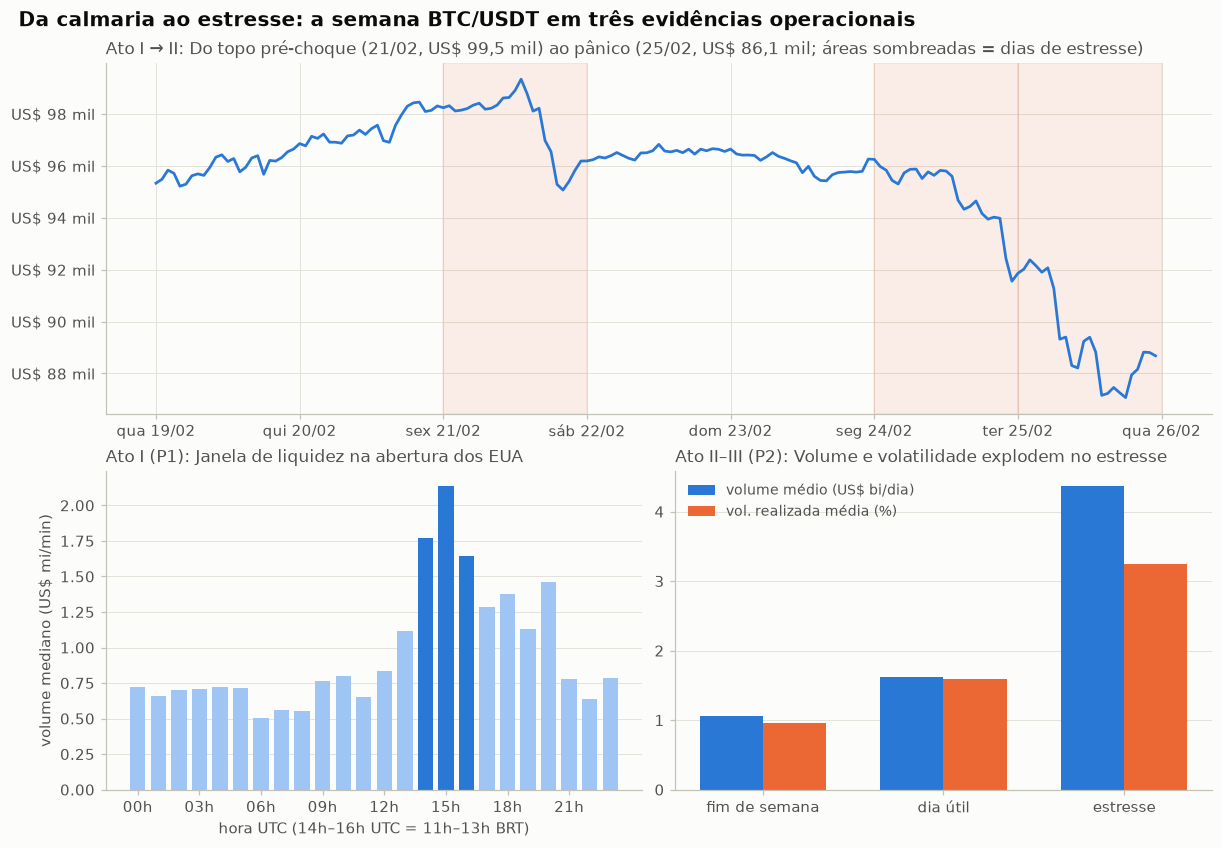

In [9]:
# Consolidação visual dos 3 Atos para a apresentação executiva
fig = plt.figure(figsize=(11, 7.6))
gs = fig.add_gridspec(2, 2, height_ratios=[1.1, 1.0])

# Ato 1: Preço e regime diário
ax_top = fig.add_subplot(gs[0, :])
hourly = bars_1m.resample("1h").agg({"close": "last", "volume_usd": "sum"})
ax_top.plot(hourly.index, hourly["close"], color=BLUE, linewidth=1.8, label="preço BTC/USDT (1h)")
for _, row in daily.iterrows():
    if row["tipo"] == "estresse":
        d0 = pd.Timestamp(row["date_str"], tz="UTC")
        ax_top.axvspan(d0, d0 + pd.Timedelta(days=1), color=ORANGE, alpha=0.10)
ax_top.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"US$ {br(v/1e3, 0)} mil"))
ax_top.xaxis.set_major_locator(mdates.DayLocator())
ax_top.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: day_label(pd.Timestamp(mdates.num2date(v)))))
ax_top.set_title("Ato I → II: Do topo pré-choque (21/02, US$ 99,5 mil) ao pânico (25/02, US$ 86,1 mil; áreas sombreadas = dias de estresse)")

# Ato 2: Liquidez intradiária vs Volatilidade (P1)
ax_bl = fig.add_subplot(gs[1, 0])
by_hr = compute_hourly_profile(bars_1m, tz_offset_hours=0)
colors_hr = [BLUE if h in (14, 15, 16) else "#9ec5f4" for h in by_hr.index]
ax_bl.bar(by_hr.index, by_hr["volume_usd_med"] / 1e6, color=colors_hr, width=0.75)
ax_bl.set_xticks(range(0, 24, 3), [f"{h:02d}h" for h in range(0, 24, 3)])
ax_bl.set_xlabel("hora UTC (14h–16h UTC = 11h–13h BRT)")
ax_bl.set_ylabel("volume mediano (US$ mi/min)")
ax_bl.set_title("Ato I (P1): Janela de liquidez na abertura dos EUA")
ax_bl.grid(axis="x", visible=False)

# Ato 3: Risco por regime vs capacidade (P2)
ax_br = fig.add_subplot(gs[1, 1])
reg = daily.groupby("tipo")[["volume_usd", "vol_realizada_pct"]].mean().reindex(["fim de semana", "dia útil", "estresse"])
x = np.arange(len(reg))
w = 0.35
ax_br.bar(x - w/2, reg["volume_usd"] / 1e9, width=w, color=BLUE, label="volume médio (US$ bi/dia)")
ax_br.bar(x + w/2, reg["vol_realizada_pct"], width=w, color=ORANGE, label="vol. realizada média (%)")
ax_br.set_xticks(x, reg.index)
ax_br.set_title("Ato II–III (P2): Volume e volatilidade explodem no estresse")
ax_br.legend(loc="upper left", fontsize=9)
ax_br.grid(axis="x", visible=False)

headline(fig, "Da calmaria ao estresse: a semana BTC/USDT em três evidências operacionais")
plt.show()


### Matriz de Decisão Consolidada para a Mesa de Execução

| Alavanca da Mesa | Evidência Empírica (CP2 + CP3) | Ação Operacional Recomendada |
|---|---|---|
| **Janela de execução (TWAP/VWAP)** | Pico às **15h UTC (12h BRT)** com US$ 2,13 mi/min vs 06h UTC com US$ 0,51 mi/min (**4,2×**); Spearman volume × amplitude = **0,83** | Programar execuções grandes preferencialmente entre **14h e 16h UTC**, obrigatoriamente **fatiadas** (TWAP/VWAP) para diluir o impacto da volatilidade simultânea. |
| **Limites de risco e *slippage*** | Em estresse (21, 24 e 25/02), volatilidade realizada dobra (**2,0×**) e movimentos > 3σ ocorrem **1,87 %** do tempo (≈ 7× a curva Normal). Volatilidade de `t+1` é previsível em *walk-forward* (`Ridge completo`: $R^2 = 0{,}385$, Spearman $= 0{,}616$) | Calibrar limites de *slippage* e *stop* dinamicamente pela **volatilidade prevista** (`Ridge`) e realizada em janela móvel, abandonando bandas fixas baseadas em desvio-padrão normal. |
| **Capacidade operacional e infraestrutura** | 25/02 atingiu **10,3 milhões de negócios** (37 % da semana) e quase 10 mil ordens ≥ US$ 100 mil (**4,5×** um dia útil) | Dimensionar ingestão e roteamento para pelo menos **4×–5×** o volume de um dia útil normal sem queda de latência. |
| **Uso de sinais preditivos (OFI)** | Correlação OFI × retorno contemporâneo = **0,388**, mas cai para **0,022** no minuto seguinte; direção em `1min` e `1s` não vence custos *taker* (2–10 bps) | **Não operar** estratégia direcional pura sobre OFI; usar apenas como sinal auxiliar para evitar cruzar o *spread* contra fluxo extremo imediato. |

---
## 5. Síntese de Ética, Licença e LGPD

A análise completa encontra-se em [`ETHICS_LGPD.md`](../ETHICS_LGPD.md):
- **LGPD (art. 5º, I):** base 100 % anônima de negócios públicos; não há dados pessoais ou identificação de titulares, e nenhum dado cadastral/KYC é cruzado.
- **Licença:** uso estritamente acadêmico sem redistribuição (`data/` no `.gitignore`, reprodutibilidade via commit fixado `c90f6087` e SHA-256).
- **Vieses e riscos:** semana atípica de choque (Bybit), única corretora/par, 7 dias de amostra horária, reconstrução aproximada de ordens agressoras e risco de perda líquida caso sinais direcionais fracos sejam operados acima dos custos de transação.
